In [1]:
import scanpy as sc
from scipy import sparse
import pandas as pd
import scarches as sca
import os

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lightning_fabric.utilities.seed:[rank: 0] Global seed set to 0
 captum (see https://github.com/pytorch/captum).


In [2]:
ref_model_dir = "./HLCA_reference_model"

In [3]:
query_prefix = "/lustre/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/HLCA_extended/extension_datasets/ready/subsetted/"

In [4]:
query_paths = {"Sheppard_2020":"tsukui_sub.h5ad"}

In [5]:
query_batch = "Sheppard_2020"

In [6]:
max_kl_weight = 0.1

In [7]:
surgery_model_dir = f"./{query_batch}_kl{max_kl_weight}"
if not os.path.isdir(surgery_model_dir):
    print("Creating directory", surgery_model_dir)
    os.makedirs(surgery_model_dir)

### Load and prep reference:

In [8]:
adata_ref = sc.read_h5ad("../../../data/HLCA_full_v1.1_emb.h5ad")

In [9]:
# subset
adata_ref = adata_ref[adata_ref.obs.core_or_extension == "core", :].copy()
# remove all obs variables that have no entries anymore (i.e. obs columns that were only relevant for the HLCA extension)
cols_to_drop = [
    col for col in adata_ref.obs.columns if adata_ref.obs[col].isnull().all()
]
adata_ref.obs.drop(columns=cols_to_drop, inplace=True)

In [10]:
adata_ref.shape

(584944, 30)

### Load and prep query:

In [8]:
adata_query_unprep = sc.read_h5ad(query_prefix + query_paths[query_batch])

In [9]:
adata_query_unprep.X = sparse.csr_matrix(adata_query_unprep.X)
del adata_query_unprep.obsm
del adata_query_unprep.varm

In [10]:
adata_query_unprep.X[:10,:10].toarray()

array([[ 0.,  1.,  0.,  0.,  7.,  0.,  1.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  4.,  0.,  0.,  0.,  0.,  0.],
       [ 0.,  4.,  0.,  1.,  1.,  0.,  0.,  0.,  1.,  0.],
       [ 0.,  9.,  0.,  2.,  1.,  2.,  1.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  1.,  0.,  4.,  0.,  0.,  0.],
       [ 0., 10.,  0.,  4.,  1.,  1.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  2.,  2.,  0.,  2.,  0.,  0.,  0.,  0.],
       [ 0.,  2.,  0.,  2.,  0.,  1.,  0.,  0.,  0.,  0.],
       [ 0., 13.,  0.,  5.,  2.,  3.,  3.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]], dtype=float32)

In [11]:
ref_model_features = pd.read_csv(
    (f"{ref_model_dir}/var_names.csv"), header=None
)

In [12]:
adata_query_unprep.var

,n_counts,gene_symbols,ensembl
FGR,13117.0,nan,ENSG00000000938
CFH,124516.0,nan,ENSG00000000971
HS3ST1,2423.0,nan,ENSG00000002587
TMEM176A,48165.0,nan,ENSG00000002933
TFPI,99852.0,nan,ENSG00000003436
...,...,...,...
MUC7,NaN,MUC7,ENSG00000171195
SPRR2E,NaN,SPRR2E,ENSG00000203785
TRAV8-6,NaN,TRAV8-6,ENSG00000211795
TRAV26-2,NaN,TRAV26-2,ENSG00000211812


In [13]:
ref_model_features.head(5)

,0
0,ENSG00000000938
1,ENSG00000000971
2,ENSG00000002587
3,ENSG00000002933
4,ENSG00000003436


In [14]:
(adata_query_unprep.var.ensembl.isin(ref_model_features[0])).sum()

2000

In [15]:
adata_query_unprep.var['gene_symbol'] = adata_query_unprep.var.index
adata_query_unprep.var.index = adata_query_unprep.var.ensembl

In [16]:
adata_query_unprep.var.head(5)

,n_counts,gene_symbols,ensembl,gene_symbol
ensembl,,,,
ENSG00000000938,13117.0,nan,ENSG00000000938,FGR
ENSG00000000971,124516.0,nan,ENSG00000000971,CFH
ENSG00000002587,2423.0,nan,ENSG00000002587,HS3ST1
ENSG00000002933,48165.0,nan,ENSG00000002933,TMEM176A
ENSG00000003436,99852.0,nan,ENSG00000003436,TFPI


In [17]:
adata_query = sca.models.SCANVI.prepare_query_anndata(
    adata=adata_query_unprep, reference_model=ref_model_dir, inplace=False
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   
INFO     Found 100.0% reference vars in query data.                                                                


In [18]:
adata_query

AnnData object with n_obs × n_vars = 80020 × 2000
    obs: 'sample', 'cond', 'n_counts', 'n_genes', 'percent_mito', 'condition', 'study', 'dataset', 'subject_ID', 'original_celltype_ann'
    var: 'n_counts', 'gene_symbols', 'ensembl', 'gene_symbol'

### Load reference model and set relevant query variables:

In [22]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model_dir,
    freeze_dropout=True,
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scvi/data/fields/_scanvi.py:91: UserWarning: Missing labels key scanvi_label. Filling in with unlabeled category unlabeled.
  warnings.warn(


In [23]:
surgery_model.registry_["setup_args"]

{'labels_key': 'scanvi_label',
 'unlabeled_category': 'unlabeled',
 'layer': None,
 'batch_key': 'dataset',
 'size_factor_key': None,
 'categorical_covariate_keys': None,
 'continuous_covariate_keys': None}

In [19]:
adata_query.obs['dataset'] = query_batch

In [20]:
adata_query.obs['scanvi_label'] = "unlabeled"

In [21]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model_dir,
    freeze_dropout=True,
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   


## Map:

### perform surgery

In [27]:
surgery_epochs = 500
early_stopping_kwargs_surgery = {
    "early_stopping_monitor": "elbo_train",
    "early_stopping_patience": 10,
    "early_stopping_min_delta": 0.001,
    "plan_kwargs": {"weight_decay": 0.0, "max_kl_weight":max_kl_weight},
}

In [28]:
surgery_model.train(max_epochs=surgery_epochs, **early_stopping_kwargs_surgery)

INFO     Training for 500 epochs.                                                                                  


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_ ...
  rank_zero_warn(
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Li

Epoch 500/500: 100%|██████████| 500/500 [2:39:49<00:00,  9.41s/it, loss=611, v_num=1]  

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=500` reached.


Epoch 500/500: 100%|██████████| 500/500 [2:39:49<00:00, 19.18s/it, loss=611, v_num=1]


In [29]:
surgery_model.save(surgery_model_dir, overwrite=True)

load model if starting from here:

In [22]:
surgery_model = sca.models.SCANVI.load(
    surgery_model_dir, adata_query
) 

INFO     File ./Sheppard_2020_kl0.1/model.pt already downloaded                                                    


### obtain query latent embedding:

In [31]:
adata_query_latent = sc.AnnData(surgery_model.get_latent_representation(adata_query))

In [32]:
adata_query_latent.obs = adata_query.obs.loc[adata_query.obs.index, :]

### combine reference and query embedding into one joint embedding:

In [33]:
adata_query_latent.obs["core_or_extension"] = "extension"

In [34]:
combined_emb = sc.concat(
    (adata_ref, adata_query_latent), index_unique=None, join="outer"
) 

As the data concatenation might have resulted in some mixed dtype obs columns, we will convert those to strings here to prevent writing errors below.

In [35]:
for cat in combined_emb.obs.columns:
    if isinstance(combined_emb.obs[cat].values, pd.Categorical):
        pass
    elif pd.api.types.is_float_dtype(combined_emb.obs[cat]):
        pass
    else:
        print(
            f"Setting obs column {cat} (not categorical neither float) to strings to prevent writing error."
        )
        combined_emb.obs[cat] = combined_emb.obs[cat].astype(str)

Setting obs column is_primary_data (not categorical neither float) to strings to prevent writing error.
Setting obs column core_or_extension (not categorical neither float) to strings to prevent writing error.
Setting obs column dataset (not categorical neither float) to strings to prevent writing error.
Setting obs column sample (not categorical neither float) to strings to prevent writing error.
Setting obs column scanvi_label (not categorical neither float) to strings to prevent writing error.
Setting obs column study (not categorical neither float) to strings to prevent writing error.


### neighbor graph + visualization of joint embedding

In [36]:
sc.pp.neighbors(combined_emb, n_neighbors=30)
sc.tl.umap(combined_emb)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


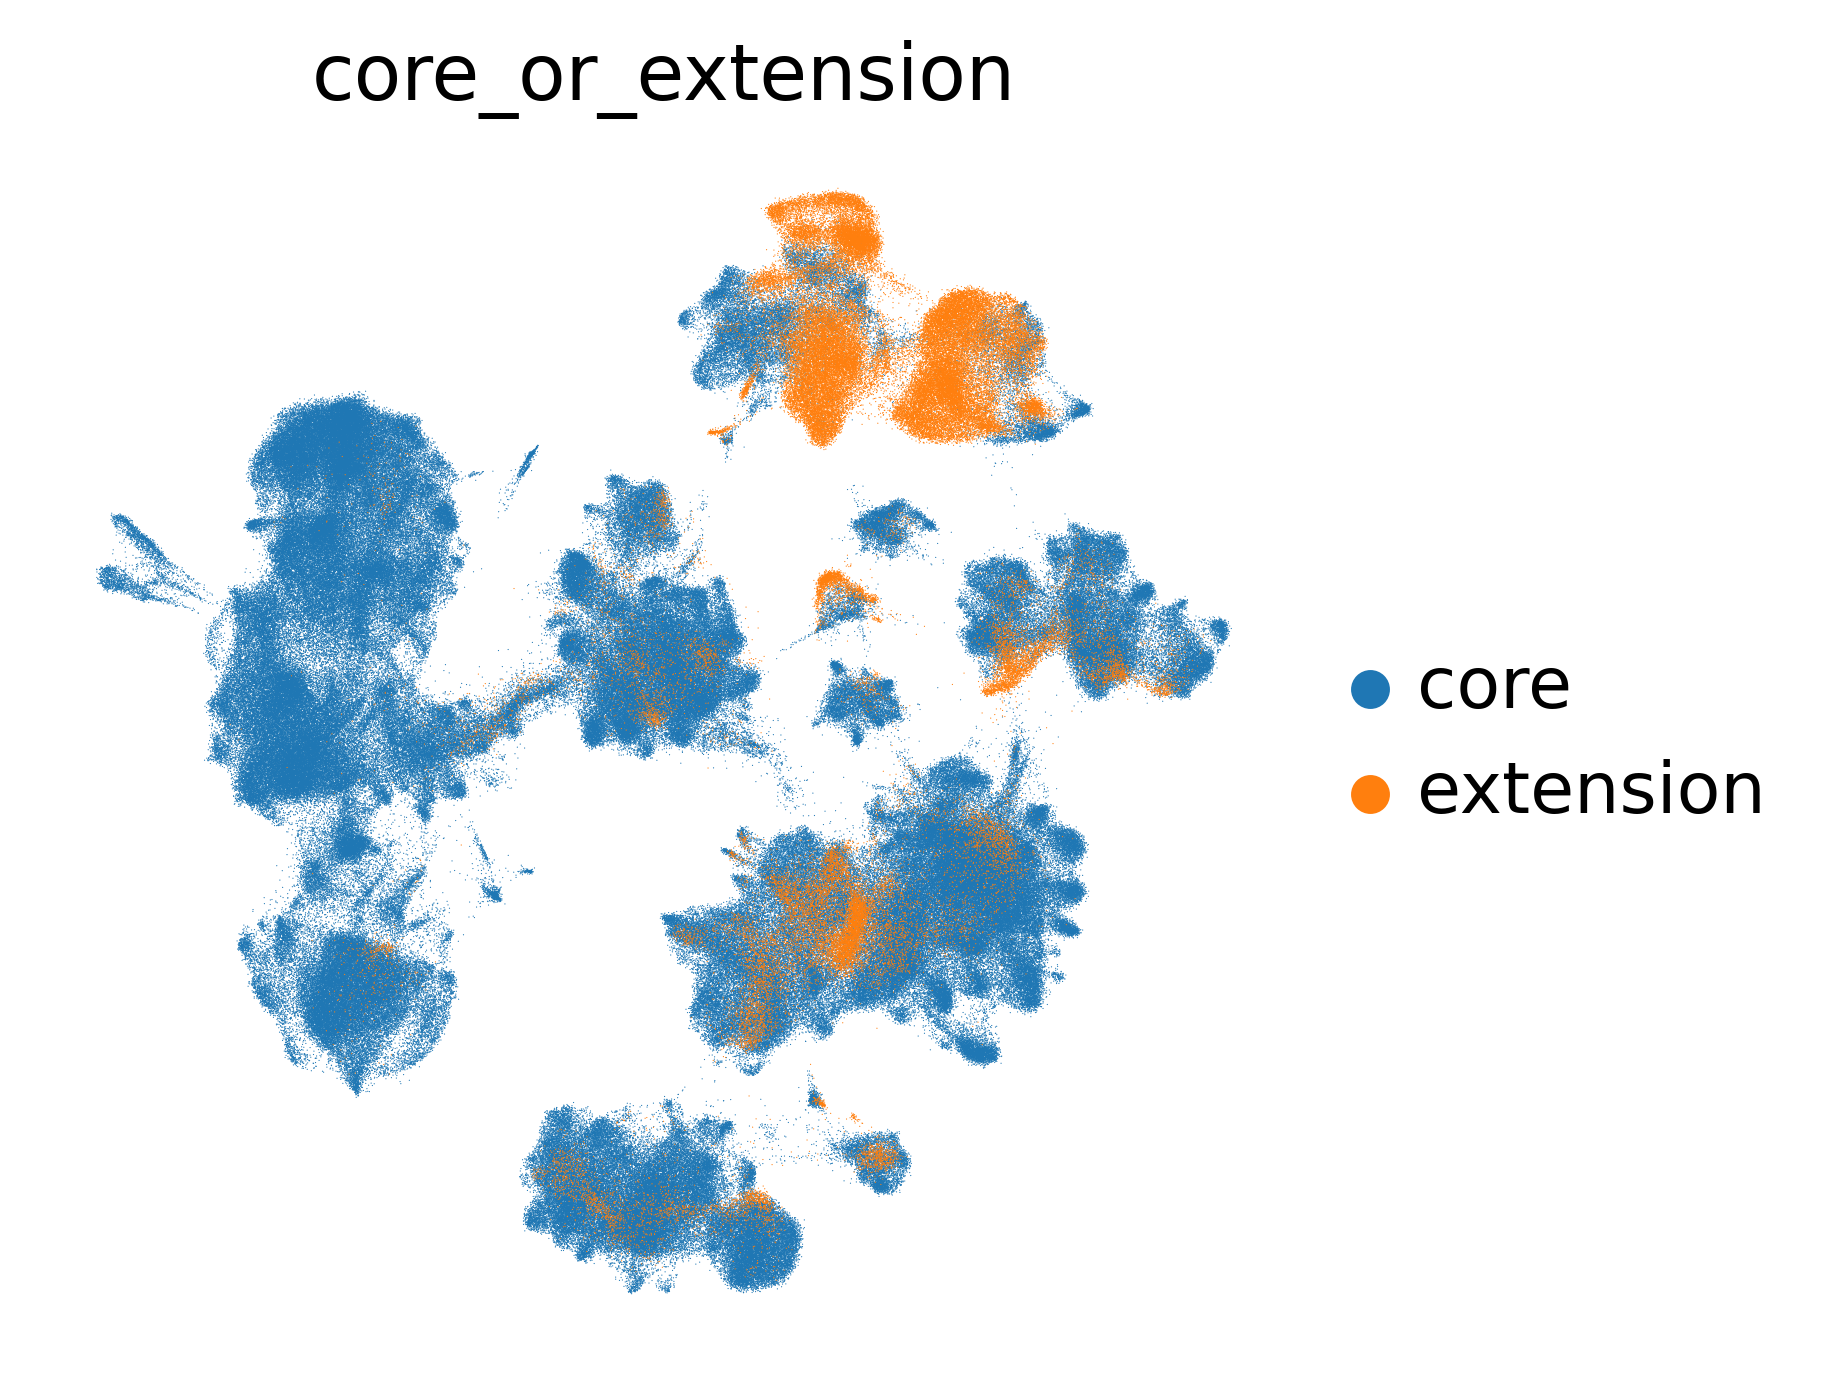

In [37]:
sc.pl.umap(combined_emb, color="core_or_extension", frameon=False, wspace=0.6)

In [38]:
combined_emb.write_h5ad(os.path.join(surgery_model_dir, f"combined_embedding_klweight_{max_kl_weight}.h5ad"))

In [24]:
surgery_model.summary_stats

n_batch: 15
n_cells: 80020
n_extra_categorical_covs: 0
n_extra_continuous_covs: 0
n_labels: 29
n_vars: 2000

In [26]:
surgery_model.get_likelihood_parameters

ScanVI Model with the following params: 
unlabeled_category: unlabeled, n_hidden: 128, n_latent: 30, n_layers: 2, dropout_rate: 0.1, dispersion: gene, 
gene_likelihood: nb
Training status: Trained
Model's adata is minified?: False

<bound method RNASeqMixin.get_likelihood_parameters of >

In [35]:
surgery_model.registry_

{'scvi_version': '0.20.1',
 'model_name': 'SCANVI',
 'setup_args': {'labels_key': 'scanvi_label',
  'unlabeled_category': 'unlabeled',
  'layer': None,
  'batch_key': 'dataset',
  'size_factor_key': None,
  'categorical_covariate_keys': None,
  'continuous_covariate_keys': None},
 'field_registries': defaultdict(dict,
             {'X': {'data_registry': {'attr_name': 'X', 'attr_key': None},
               'state_registry': {'n_obs': 80020,
                'n_vars': 2000,
                'column_names': array(['ENSG00000000938', 'ENSG00000000971', 'ENSG00000002587',
                       'ENSG00000002933', 'ENSG00000003436', 'ENSG00000004776',
                       'ENSG00000004799', ..., 'ENSG00000278196', 'ENSG00000279576',
                       'ENSG00000280721', 'ENSG00000281103', 'ENSG00000282122',
                       'ENSG00000282988', 'ENSG00000283063'], dtype=object)},
               'summary_stats': {'n_vars': 2000, 'n_cells': 80020}},
              'batch': {'data_regis

In [31]:
surgery_model.history

{'train_loss_step':       train_loss_step
 epoch                
 0          581.852661
 1          583.490723
 2          653.366211
 3          615.549438
 4          606.815552
 ...               ...
 495        609.108032
 496        621.357788
 497        601.206177
 498        621.054504
 499        591.912781
 
 [500 rows x 1 columns],
 'train_loss_epoch':       train_loss_epoch
 epoch                 
 0            626.95459
 1           615.704102
 2           610.407166
 3           607.274902
 4           605.239868
 ...                ...
 495         609.559387
 496         609.540771
 497         609.561768
 498         609.557495
 499          609.57428
 
 [500 rows x 1 columns],
 'elbo_train':        elbo_train
 epoch            
 0      726.400818
 1        714.9776
 2      709.520508
 3      706.287659
 4      704.206787
 ...           ...
 495     699.93335
 496    699.901917
 497    699.927124
 498    699.914917
 499    699.935913
 
 [500 rows x 1 columns],
 'recons